In [28]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, ops
import matplotlib.pyplot as plt
import os
import numpy as np

In [29]:
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [30]:
dataset_path = '/kaggle/input/handwritten-math-symbols/dataset'
labels = []
for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file == '.directory':
            continue
        label = os.path.basename(root)
        file_path = os.path.join(root, file)
        labels.append(label)

In [31]:
label_mapping = {
    'add': '+',
    'dec': '.',
    'div': '/',
    'eq': '=',
    'mul': '*',
    'sub': '-'
}

In [32]:
labels = [label_mapping.get(label, label) for label in labels]

In [33]:
characters = set(char for label in labels for char in label)
characters = sorted(list(characters))

In [34]:
char_to_num = layers.StringLookup(vocabulary=list(characters), mask_token=None)

num_to_char = layers.StringLookup(
    vocabulary=char_to_num.get_vocabulary(), mask_token=None, invert=True
)

In [35]:
labels = tf.strings.as_string(labels)

In [36]:
labels = char_to_num(labels)

In [38]:
dataset_path = '/kaggle/input/handwritten-math-symbols/dataset'
image_paths = []
for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file == '.directory':
            continue
        file_path = os.path.join(root, file)
        image_paths.append(file_path)

In [39]:
def preprocess_image(image_path):
    img = tf.io.read_file(image_path)
    img = tf.io.decode_png(img, channels=1)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, [32, 32])
    img = tf.transpose(img, perm=[1, 0, 2])
    return img

processed_images = [preprocess_image(path) for path in image_paths]

num_images = len(processed_images)
images = tf.stack(processed_images)

In [40]:
labels = [[label] for label in labels]

In [41]:
labels = tf.reshape(labels, shape=(num_images, 1))

In [42]:
dataset = tf.data.Dataset.from_tensor_slices((images, labels))

In [43]:
train_ds, val_ds = keras.utils.split_dataset(dataset, left_size=.8, right_size=.2)

In [44]:
buffer = tf.data.AUTOTUNE
train_ds = train_ds.shuffle(buffer_size=train_ds.cardinality()).batch(64, drop_remainder=True).prefetch(buffer_size=buffer)
val_ds = val_ds.shuffle(buffer_size=val_ds.cardinality()).batch(64, drop_remainder=True).prefetch(buffer_size=buffer)

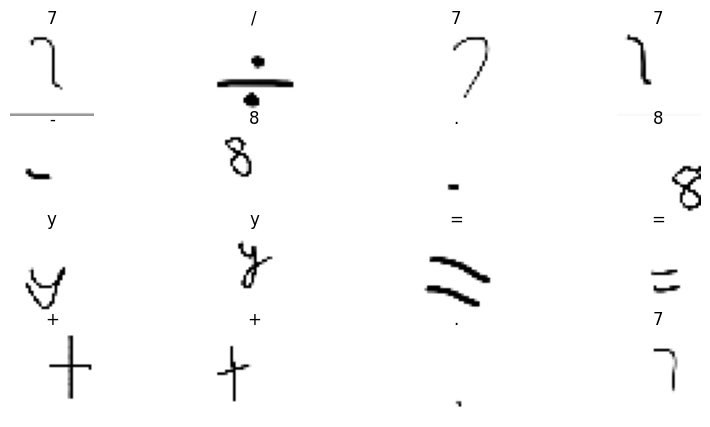

In [45]:
_, ax = plt.subplots(4, 4, figsize=(10, 5))
for images, labels in train_ds.take(1):
    for i in range(16):
        img = (images[i] * 255).numpy().astype("uint8")
        label = tf.strings.reduce_join(num_to_char(labels[i])).numpy().decode("utf-8")
        ax[i // 4, i % 4].imshow(img[:, :, 0].T, cmap="gray")
        ax[i // 4, i % 4].set_title(label)
        ax[i // 4, i % 4].axis("off")
plt.show()

In [46]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Shape: height, width, channels.
input_shape = (32, 32, 1)
input_image = layers.Input(shape=input_shape)

x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_image)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)  # Downsample spatial dimensions.
x = layers.Dropout(0.25)(x)

x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.25)(x)

x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)

# Reshape CNN features for the RNN.
x = layers.Reshape(target_shape=(-1, x.shape[2] * x.shape[3]))(x)

x = layers.Bidirectional(layers.LSTM(256, return_sequences=True, dropout=0.3))(x)
x = layers.LayerNormalization()(x)
x = layers.Bidirectional(layers.LSTM(128, return_sequences=True, dropout=0.3))(x)
x = layers.LayerNormalization()(x)

x = layers.Dense(20)(x)

model = models.Model(input_image, x)

In [47]:
model.compile(optimizer=tf.keras.optimizers.RMSprop(), loss=tf.keras.losses.CTC, metrics=['accuracy'])

In [ ]:
model.fit(train_ds, validation_data=val_ds, epochs=100)

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.0946 - loss: 3.5818 - val_accuracy: 0.0000e+00 - val_loss: 17.7344
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.2151 - loss: 0.5139 - val_accuracy: 0.0000e+00 - val_loss: 10.9694
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.2377 - loss: 0.2526 - val_accuracy: 0.0000e+00 - val_loss: 11.7384
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.2426 - loss: 0.1790 - val_accuracy: 0.0000e+00 - val_loss: 10.6669
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.2461 - loss: 0.1337 - val_accuracy: 0.0203 - val_loss: 10.4589
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.2498 - loss: 0.1026 - val_accuracy: 0.0144 - val_loss: 10.1019
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.2529 - loss: 0.0813 - val_accuracy: 0.0285 - val_loss: 10.4604
Epoch 8/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0

In [ ]:
def ctc_decode(y_pred, input_length, greedy=True, beam_width=100, top_paths=1):
    input_shape = ops.shape(y_pred)
    num_samples, num_steps = input_shape[0], input_shape[1]
    y_pred = ops.log(ops.transpose(y_pred, axes=[1, 0, 2]) + keras.backend.epsilon())
    input_length = ops.cast(input_length, dtype="int32")

    if greedy:
        (decoded, log_prob) = tf.nn.ctc_greedy_decoder(
            inputs=y_pred, sequence_length=input_length
        )
    else:
        (decoded, log_prob) = tf.compat.v1.nn.ctc_beam_search_decoder(
            inputs=y_pred,
            sequence_length=input_length,
            beam_width=beam_width,
            top_paths=top_paths,
        )
    decoded_dense = []
    for st in decoded:
        st = tf.SparseTensor(st.indices, st.values, (num_samples, num_steps))
        decoded_dense.append(tf.sparse.to_dense(sp_input=st, default_value=-1))
    return (decoded_dense, log_prob)

prediction_model = keras.models.Model(
    inputs=input_image, outputs=x
)

def decode_batch_predictions(pred, max_length=1):
    input_len = np.ones(pred.shape[0]) * pred.shape[1]
    # Greedy CTC decoding; beam search is also available.
    results = ctc_decode(pred, input_length=input_len, greedy=True)[0][0][
        :, :max_length
    ]
    output_text = []
    for res in results:
        res = tf.strings.reduce_join(num_to_char(res)).numpy().decode("utf-8")
        output_text.append(res)
    return output_text

for images, labels in train_ds.take(1):

    preds = prediction_model.predict(images)
    pred_texts = decode_batch_predictions(preds)

    orig_texts = []
    for label in labels:
        label = tf.strings.reduce_join(num_to_char(label)).numpy().decode("utf-8")
        orig_texts.append(label)

    _, ax = plt.subplots(4, 4, figsize=(15, 5))
    ax = ax.flatten()
    num_to_plot = min(len(pred_texts), len(ax))
    for i in range(num_to_plot):
        img = (images[i, :, :, 0] * 255).numpy().astype(np.uint8)
        img = img.T
        title = f"Prediction: {pred_texts[i]}"
        ax[i].imshow(img, cmap="gray")
        ax[i].set_title(title)
        ax[i].axis("off")

plt.tight_layout()
plt.show()